# Báo cáo bộ dữ liệu Quotes

## 1. Nguồn và phương pháp thu thập
- Website: https://quotes.toscrape.com
- Công cụ: Python, requests, BeautifulSoup
- Source code: crawler.py
- Cách làm: duyệt lần lượt các trang, lấy nội dung câu trích dẫn, tác giả và các thẻ (tags)
- Kết quả: lưu vào data.json

## 2. Mô tả bộ dữ liệu

In [9]:
import json
import pandas as pd
import matplotlib.pyplot as plt
from collections import Counter

with open("data.json", encoding="utf-8") as f:
    data = json.load(f)

df = pd.DataFrame(data)
print("Tổng số điểm dữ liệu:", len(df))
df.head()

Tổng số điểm dữ liệu: 100


,text,author,tags,id
0,“The world as we have created it is a process ...,Albert Einstein,"[change, deep-thoughts, thinking, world]",1
1,"“It is our choices, Harry, that show what we t...",J.K. Rowling,"[abilities, choices]",2
2,“There are only two ways to live your life. On...,Albert Einstein,"[inspirational, life, live, miracle, miracles]",3
3,"“The person, be it gentleman or lady, who has ...",Jane Austen,"[aliteracy, books, classic, humor]",4
4,"“Imperfection is beauty, madness is genius and...",Marilyn Monroe,"[be-yourself, inspirational]",5


In [10]:
df.info()
print("Giá trị thiếu:\n", df.isnull().sum())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100 entries, 0 to 99
Data columns (total 4 columns):
 #   Column  Non-Null Count  Dtype 
---  ------  --------------  ----- 
 0   text    100 non-null    object
 1   author  100 non-null    object
 2   tags    100 non-null    object
 3   id      100 non-null    int64 
dtypes: int64(1), object(3)
memory usage: 3.3+ KB
Giá trị thiếu:
 text      0
author    0
tags      0
id        0
dtype: int64


## 3. Thống kê cơ bản

In [11]:
df["text_length"] = df["text"].str.len()
df["num_tags"] = df["tags"].apply(len)

print("Số tác giả khác nhau:", df["author"].nunique())
all_tags = [t for tags in df["tags"] for t in tags]
print("Số thẻ khác nhau:", len(set(all_tags)))
df[["text_length", "num_tags"]].describe()

Số tác giả khác nhau: 50
Số thẻ khác nhau: 137


,text_length,num_tags
count,100.000000,100.000000
mean,122.270000,2.320000
std,133.747376,1.681029
min,34.000000,0.000000
25%,66.500000,1.000000
50%,86.000000,2.000000
75%,125.000000,3.000000
max,1084.000000,8.000000


### 3.1. Top 10 tác giả có nhiều câu nhất

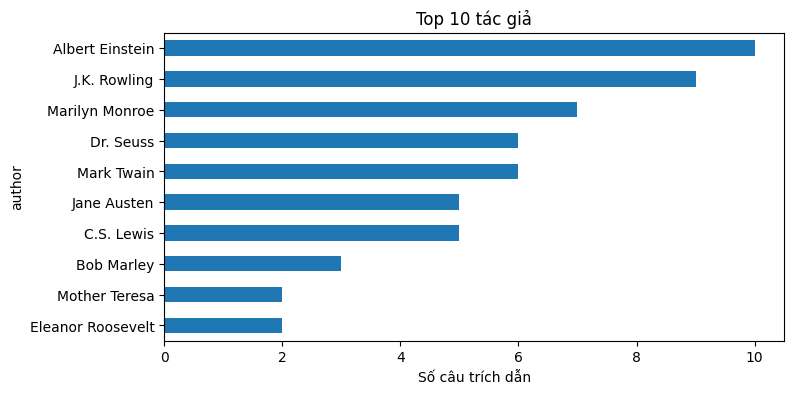

,count
author,
Albert Einstein,10
J.K. Rowling,9
Marilyn Monroe,7
Dr. Seuss,6
Mark Twain,6
Jane Austen,5
C.S. Lewis,5
Bob Marley,3
Mother Teresa,2


In [12]:
top_authors = df["author"].value_counts().head(10)
top_authors.plot(kind="barh", figsize=(8, 4)).invert_yaxis()
plt.xlabel("Số câu trích dẫn")
plt.title("Top 10 tác giả")
plt.show()
top_authors

### 3.2. Top 10 thẻ phổ biến nhất

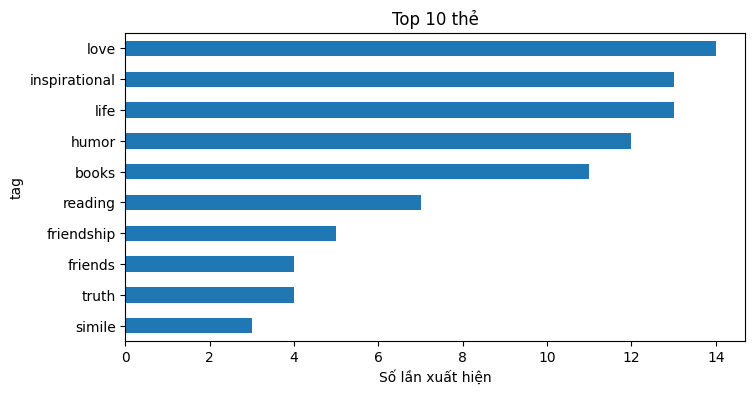

,tag,count
0,love,14
1,inspirational,13
2,life,13
3,humor,12
4,books,11
5,reading,7
6,friendship,5
7,friends,4
8,truth,4
9,simile,3


In [13]:
tag_count = Counter(all_tags).most_common(10)
tags_df = pd.DataFrame(tag_count, columns=["tag", "count"])
tags_df.plot(kind="barh", x="tag", y="count", figsize=(8, 4), legend=False).invert_yaxis()
plt.xlabel("Số lần xuất hiện")
plt.title("Top 10 thẻ")
plt.show()
tags_df

### 3.3. Phân bố độ dài câu trích dẫn

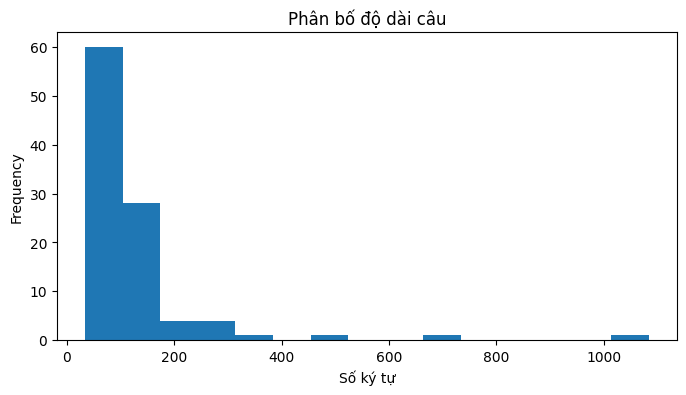

In [14]:
df["text_length"].plot(kind="hist", bins=15, figsize=(8, 4))
plt.xlabel("Số ký tự")
plt.title("Phân bố độ dài câu")
plt.show()